In [0]:
%python
# ==============================================================================
# STEP 0: SETUP — INSTALAR PYTORCH (BUILD CPU)
# ==============================================================================
# Objectivo: Instalar o PyTorch (versão CPU, sem dependências CUDA) no
#            ambiente do notebook.
# Input:  Índice CPU oficial do PyTorch (download.pytorch.org)
# Output: torch importável na sessão
#
# Nota: instalação notebook-scoped — voltar a executar esta célula (e as
#       seguintes) em cada nova sessão / após reinício do Python.
# ==============================================================================

%pip install --quiet torch --index-url https://download.pytorch.org/whl/cpu
dbutils.library.restartPython()

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
%python
# ==============================================================================
# STEP 1: INGESTÃO DOS DADOS — TINYSTORIES (HUGGING FACE)
# ==============================================================================
# Objectivo: Descarregar o dataset TinyStories (roneneldan/TinyStories) do
#            Hugging Face e aterrissá-lo como tabela Delta bronze.
# Input:  Ficheiros Parquet públicos da HF (splits train: 4 shards, validation: 1 shard)
# Output: Tabela Delta workspace.default.tinystories_raw (colunas: text, split)
#         Ficheiros brutos em /Volumes/workspace/default/tmp/tinystories/
#
# Operações:
#   - Listar os shards Parquet através da API da Hugging Face
#   - Descarregar os 4 shards de treino + 1 de validação para o volume
#   - Ler os Parquet com Spark e escrever na tabela Delta bronze
#   - Validar a contagem de exemplos por split
# ==============================================================================

import os
import time
import requests
from pyspark.sql import functions as F

VOLUME_DIR = "/Volumes/workspace/default/tmp/tinystories"
TABLE = "workspace.default.tinystories_raw"

os.makedirs(VOLUME_DIR, exist_ok=True)


def download(url: str, dest: str) -> None:
    """Descarrega um ficheiro com retoma simples (ignora se já existe)."""
    if os.path.exists(dest) and os.path.getsize(dest) > 0:
        print(f"  já existe, a saltar: {os.path.basename(dest)}")
        return
    t0 = time.time()
    with requests.get(url, stream=True, timeout=300) as r:
        r.raise_for_status()
        with open(dest, "wb") as f:
            for chunk in r.iter_content(8 * 1024 * 1024):
                f.write(chunk)
    print(f"  {os.path.basename(dest)}: {os.path.getsize(dest)/1e6:.1f} MB em {time.time()-t0:.0f}s")


# --- 1) Listar e descarregar os shards de cada split -------------------------
shards = []
for split in ["train", "validation"]:
    urls = requests.get(
        f"https://huggingface.co/api/datasets/roneneldan/TinyStories/parquet/default/{split}",
        timeout=30,
    ).json()
    print(f"Split '{split}': {len(urls)} shard(s) a descarregar")
    for i, url in enumerate(urls):
        dest = f"{VOLUME_DIR}/{split}_{i}.parquet"
        download(url, dest)
        shards.append((split, dest))

# --- 2) Ler os Parquet e aterrar como Delta bronze ---------------------------
df = None
for split, path in shards:
    part = spark.read.parquet(path).withColumn("split", F.lit(split))
    df = part if df is None else df.unionByName(part)

print("Schema:", df.schema.simpleString())
df.write.format("delta").mode("overwrite").saveAsTable(TABLE)
print(f"\nTabela bronze criada: {TABLE}")

# --- 3) Validação da ingestão -------------------------------------------------
display(spark.sql(f"SELECT split, COUNT(*) AS n_exemplos FROM {TABLE} GROUP BY split"))

Split 'train': 4 shard(s) a descarregar
  train_0.parquet: 248.7 MB em 7s
  train_1.parquet: 248.2 MB em 4s
  train_2.parquet: 245.9 MB em 13s
  train_3.parquet: 248.0 MB em 2s
Split 'validation': 1 shard(s) a descarregar
  validation_0.parquet: 10.0 MB em 1s
Schema: struct<text:string,split:string>

Tabela bronze criada: workspace.default.tinystories_raw


split,n_exemplos
train,2119719
validation,21990


In [0]:
%python
# ==============================================================================
# STEP 2: ANÁLISE EXPLORATÓRIA (EDA) — TINYSTORIES
# ==============================================================================
# Objectivo: Caracterizar o corpus antes da tokenização: volume de exemplos,
#            comprimento dos textos, palavras mais frequentes e distribuição.
# Input:  Tabela Delta workspace.default.tinystories_raw (colunas: text, split)
# Output: Métricas no output da célula (tabelas e texto)
#
# Operações:
#   - Resumo por split: nº de exemplos, média/mediana/desvio-padrão de palavras
#   - Palavras mais frequentes (com e sem stopwords inglesas)
#   - Pré-visualização de 2 histórias de exemplo
# ==============================================================================

from pyspark.sql import functions as F

TABLE = "workspace.default.tinystories_raw"

STOPWORDS = {
    "the", "and", "a", "to", "was", "she", "he", "it", "her", "his", "they",
    "in", "that", "of", "said", "had", "were", "i", "you", "but", "so",
    "at", "on", "for", "with", "not", "him", "them", "my", "me", "s",
}

# --- 1) Métricas por split ----------------------------------------------------
df = spark.table(TABLE)
df_stats = (
    df.withColumn("n_palavras", F.size(F.split("text", r"\s+")))
    .withColumn("n_caracteres", F.length("text"))
    .cache()
)

resumo = df_stats.groupBy("split").agg(
    F.count("*").alias("n_exemplos"),
    F.round(F.avg("n_palavras"), 1).alias("palavras_media"),
    F.expr("percentile_approx(n_palavras, 0.5)").alias("palavras_mediana"),
    F.round(F.stddev("n_palavras"), 1).alias("palavras_desvio_padrao"),
    F.min("n_palavras").alias("palavras_min"),
    F.max("n_palavras").alias("palavras_max"),
    F.round(F.avg("n_caracteres"), 0).alias("caracteres_media"),
)
print("=== Resumo por split ===")
display(resumo)

# --- 2) Palavras mais frequentes ----------------------------------------------
tokens = (
    df.select(F.explode(F.split(F.lower("text"), r"\s+")).alias("tok"))
    .select(F.regexp_replace("tok", "[^a-z']", "").alias("palavra"))
    .where(F.length("palavra") > 0)
)

top_geral = tokens.groupBy("palavra").count().orderBy(F.desc("count")).limit(15)
print("=== Top 15 palavras (todas) ===")
display(top_geral)

top_conteudo = (
    tokens.where(~F.col("palavra").isin(list(STOPWORDS)))
    .groupBy("palavra")
    .count()
    .orderBy(F.desc("count"))
    .limit(15)
)
print("=== Top 15 palavras (sem stopwords) ===")
display(top_conteudo)

# --- 3) Pré-visualização de exemplos -----------------------------------------
print("=== Exemplos do dataset ===")
for row in df.where(F.col("split") == "train").limit(2).collect():
    print("-", row["text"][:300].replace("\n", " "), "...\n")

print(f"\nTotal de tokens no split de treino: {df_stats.where(F.col('split')=='train').agg(F.sum('n_palavras')).collect()[0][0]:,}")

=== Resumo por split ===


split,n_exemplos,palavras_media,palavras_mediana,palavras_desvio_padrao,palavras_min,palavras_max,caracteres_media
train,2119719,175.4,153,80.2,1,963,896.0
validation,21990,170.7,151,75.3,13,841,873.0


=== Top 15 palavras (todas) ===


palavra,count
the,20445310
and,18294807
to,12777682
a,11593540
was,9535383
he,8037294
she,7777248
they,6820039
it,6753449
her,4972859


=== Top 15 palavras (sem stopwords) ===


palavra,count
lily,2870431
day,2698028
mom,2289730
one,2075629
there,1910996
very,1903819
little,1857398
time,1831360
happy,1752231
is,1711031


=== Exemplos do dataset ===
- One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.  Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and  ...

- Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.  One day, Beep was driving in the park when he saw a big tree. The tree had many leaves that were falling. Bee ...


Total de tokens no split de treino: 371,713,768


In [0]:
%python
# ==============================================================================
# STEP 3: VOCABULÁRIO E TOKENIZAÇÃO
# ==============================================================================
# Objectivo: Construir o vocabulário word-level e converter todas as histórias
#            em sequências de ids de tokens (camada silver).
# Input:  Tabela Delta workspace.default.tinystories_raw (colunas: text, split)
# Output: workspace.default.tinystories_vocab  (token_id, palavra, freq)
#         workspace.default.tinystories_tokens (story_id, split, tokens, n_tokens)
#
# Operações:
#   - Tokenizar: palavras em minúsculas (com apóstrofos) + pontuação [. , ! ?]
#   - Vocabulário: palavras do treino com freq >= 5 + tokens especiais
#     (<pad>=0, <unk>=1, <eos>=2); ids atribuídos por ordem de frequência
#   - Mapear cada história para sequência de ids (<unk> para fora do vocab)
#     e acrescentar <eos> no fim
#   - Métricas: tamanho do vocabulário e taxa de <unk> (cobertura)
# ==============================================================================

from pyspark.sql import functions as F

RAW = "workspace.default.tinystories_raw"
VOCAB = "workspace.default.tinystories_vocab"
TOKENS = "workspace.default.tinystories_tokens"

MIN_FREQ = 5                                # palavras mais raras -> <unk>
PAD_ID, UNK_ID, EOS_ID = 0, 1, 2            # tokens especiais
TOKEN_PATTERN = "[a-z]+(?:'[a-z]+)?|[.,!?]"  # palavras minúsculas + pontuação

stories = spark.table(RAW).withColumn("story_id", F.md5("text"))

# --- 1) Vocabulário: palavras do treino com freq >= MIN_FREQ ------------------
word_counts = (
    stories.where(F.col("split") == "train")
    .select(F.explode(F.expr(f'regexp_extract_all(lower(text), "{TOKEN_PATTERN}", 0)')).alias("palavra"))
    .groupBy("palavra")
    .agg(F.count("*").alias("freq"))
    .cache()
)
vocab_rows = (
    word_counts.where(F.col("freq") >= MIN_FREQ)
    .orderBy(F.desc("freq"), F.asc("palavra"))
    .collect()
)
n_distintas = word_counts.count()

vocab_data = (
    [(PAD_ID, "<pad>", None), (UNK_ID, "<unk>", None), (EOS_ID, "<eos>", None)]
    + [(i + 3, r["palavra"], r["freq"]) for i, r in enumerate(vocab_rows)]
)
vocab_df = spark.createDataFrame(vocab_data, schema="token_id int, palavra string, freq long")
vocab_df.write.mode("overwrite").saveAsTable(VOCAB)

print(f"Palavras distintas no treino: {n_distintas:,}")
print(f"Palavras com freq >= {MIN_FREQ}: {len(vocab_rows):,} ({100*len(vocab_rows)/n_distintas:.1f}% do total distinto)")
print(f"Vocabulário final: {len(vocab_data):,} tokens = 3 especiais + {len(vocab_rows):,} palavras")

# --- 2) Tokenização: histórias -> sequências de ids ---------------------------
# Mapa palavra->id numa única linha (broadcast) e lookup por história,
# evita explode de 371M de tokens.
vmap_df = vocab_df.where(F.col("token_id") >= 3).agg(
    F.expr("map_from_entries(collect_list(struct(palavra, token_id)))").alias("vmap")
)

tokens_df = (
    stories.select(
        "story_id", "split",
        F.expr(f'regexp_extract_all(lower(text), "{TOKEN_PATTERN}", 0)').alias("words"),
    )
    .crossJoin(F.broadcast(vmap_df))
    .select(
        "story_id", "split",
        F.expr(f"concat(transform(words, w -> coalesce(vmap[w], {UNK_ID})), array({EOS_ID}))").alias("tokens"),
    )
    .withColumn("n_tokens", F.size("tokens"))
)
tokens_df.write.mode("overwrite").saveAsTable(TOKENS)

# --- 3) Verificação: cobertura e exemplo decodificado --------------------------
amostra = spark.table(TOKENS).where(F.col("split") == "train").sample(False, 0.05, seed=42)
cov = amostra.agg(
    F.sum("n_tokens").alias("total"),
    F.sum(F.expr("size(filter(tokens, t -> t = 1))")).alias("unk"),
).collect()[0]
print(f"\nTaxa de <unk> (amostra de 5% do treino): {100*cov['unk']/cov['total']:.2f}% de {cov['total']:,} tokens")

inv_vocab = {r[0]: r[1] for r in vocab_data}
ex = spark.table(TOKENS).where(F.col("split") == "train").orderBy("story_id").first()
print("\nExemplo de sequência (primeiros 20 tokens de uma história):")
print(" ".join(f"{t}:{inv_vocab[t]}" for t in ex["tokens"][:20]))
print(f"... ({ex['n_tokens']} tokens no total, termina em '{inv_vocab[ex['tokens'][-1]]}')")

print("\n=== Primeiras 10 entradas do vocabulário ===")
display(vocab_df.orderBy("token_id").limit(10))

Palavras distintas no treino: 47,055
Palavras com freq >= 5: 27,022 (57.4% do total distinto)
Vocabulário final: 27,025 tokens = 3 especiais + 27,022 palavras

Taxa de <unk> (amostra de 5% do treino): 0.01% de 21,643,053 tokens

Exemplo de sequência (primeiros 20 tokens de uma história):
30:one 25:day 6:, 169:jack 5:and 19:his 1414:aunt 43:were 276:walking 18:in 4:the 101:park 3:. 12:they 120:came 638:across 8:a 2916:marching 1119:band 3:.
... (188 tokens no total, termina em '<eos>')

=== Primeiras 10 entradas do vocabulário ===


token_id,palavra,freq
0,,null
1,,null
2,,null
3,.,36459483
4,the,20242021
5,and,18119227
6,",",17359980
7,to,12648916
8,a,11478219
9,was,9436767


In [0]:
%python
# ==============================================================================
# STEP 4: PARES DE TREINO (CONTEXTO -> PALAVRA SEGUINTE)
# ==============================================================================
# Objectivo: Criar os pares supervisionados para o modelo next-word-prediction:
#            entrada = janela de 16 tokens de contexto, alvo = token seguinte.
# Input:  workspace.default.tinystories_tokens (story_id, split, tokens)
#         workspace.default.tinystories_vocab (para decodificar ids -> palavras)
# Output: workspace.default.tinystories_pairs_train (amostra de 20k histórias)
#         workspace.default.tinystories_pairs_val  (amostra de 2k histórias)
#
# Operações:
#   - Amostrar histórias: 20k do treino (corpus de treino do modelo) + 2k de
#     validação — as histórias com <= 16 tokens não geram pares
#   - Para cada posição i da história: contexto = tokens[i-16:i], alvo = tokens[i]
#     (só posições com contexto completo; sem padding, sem attention mask)
#   - Guardar pares em Delta: (story_id, pos, context, target)
#   - Mostrar exemplos de par decodificados + verificação manual
# ==============================================================================

import pandas as pd
from pyspark.sql import functions as F

TOKENS = "workspace.default.tinystories_tokens"
VOCAB = "workspace.default.tinystories_vocab"
PAIRS_TRAIN = "workspace.default.tinystories_pairs_train"
PAIRS_VAL = "workspace.default.tinystories_pairs_val"

CONTEXT_SIZE = 16      # tokens de contexto (entrada do modelo)
N_HIST_TREINO = 20_000  # histórias amostradas para o treino
N_HIST_VAL = 2_000      # histórias de validação
SEED = 42

tokens_tbl = spark.table(TOKENS)


def gerar_pares(split: str, n_alvo: int, tabela: str) -> int:
    """Amostra histórias de um split e gera pares (contexto -> alvo) em Delta."""
    n_total = tokens_tbl.where(F.col("split") == split).count()
    frac = min(1.0, n_alvo / n_total)
    amostra = tokens_tbl.where(F.col("split") == split).sample(False, frac, seed=SEED)

    pares = (
        amostra.where(F.size("tokens") > CONTEXT_SIZE)
        .select(
            "story_id",
            F.expr(
                f"transform(sequence({CONTEXT_SIZE + 1}, size(tokens)), "
                f"i -> struct(i - 1 as pos, slice(tokens, i - {CONTEXT_SIZE}, {CONTEXT_SIZE}) as context, "
                f"element_at(tokens, i) as target))"
            ).alias("pares"),
        )
        .select("story_id", F.explode("pares").alias("p"))
        .select("story_id", "p.pos", "p.context", "p.target")
    )
    pares.write.mode("overwrite").saveAsTable(tabela)

    n_hist = amostra.count()
    n_pares = spark.table(tabela).count()
    print(f"{tabela}: {n_hist:,} histórias -> {n_pares:,} pares")
    return n_pares


print("=== Geração de pares ===")
gerar_pares("train", N_HIST_TREINO, PAIRS_TRAIN)
gerar_pares("validation", N_HIST_VAL, PAIRS_VAL)

# --- Exemplo de par + verificação manual ---------------------------------------
inv_vocab = {r["token_id"]: r["palavra"] for r in spark.table(VOCAB).collect()}

exemplo_id = spark.table(PAIRS_TRAIN).orderBy("story_id", "pos").select("story_id").first()[0]
hist = tokens_tbl.where(F.col("story_id") == exemplo_id).orderBy("split").first()
pares_ex = (
    spark.table(PAIRS_TRAIN)
    .where(F.col("story_id") == exemplo_id)
    .orderBy("pos")
    .limit(3)
    .collect()
)

print(f"\n=== Exemplo de pares (história {exemplo_id[:10]}...) ===")
pdf = pd.DataFrame(
    [
        {
            "pos": r["pos"],
            "contexto (palavras)": " ".join(inv_vocab[t] for t in r["context"]),
            "alvo": inv_vocab[r["target"]],
            "context (ids)": r["context"],
            "target (id)": r["target"],
        }
        for r in pares_ex
    ]
)
display(pdf)

# Verificação por método independente: o 1º par da história tem de ter
# contexto = tokens[0:16] e alvo = tokens[16] da própria sequência.
r0 = pares_ex[0]
assert list(r0["context"]) == list(hist["tokens"])[:CONTEXT_SIZE], "contexto != primeiros 16 tokens"
assert r0["target"] == hist["tokens"][CONTEXT_SIZE], "alvo != 17º token"
print("Verificação manual: contexto = tokens[0:16] e alvo = tokens[16] — OK ✔")

=== Geração de pares ===
workspace.default.tinystories_pairs_train: 20,000 histórias -> 3,747,482 pares
workspace.default.tinystories_pairs_val: 2,047 histórias -> 369,679 pares

=== Exemplo de pares (história 000312e0ad...) ===


pos,contexto (palavras),alvo,context (ids),target (id)
16,"once upon a time , there was a fat cat named danny . he liked to",sleep,"List(42, 47, 8, 35, 6, 32, 9, 8, 1463, 213, 71, 1969, 3, 10, 114, 7)",648
17,"upon a time , there was a fat cat named danny . he liked to sleep",in,"List(47, 8, 35, 6, 32, 9, 8, 1463, 213, 71, 1969, 3, 10, 114, 7, 648)",18
18,"a time , there was a fat cat named danny . he liked to sleep in",the,"List(8, 35, 6, 32, 9, 8, 1463, 213, 71, 1969, 3, 10, 114, 7, 648, 18)",4


Verificação manual: contexto = tokens[0:16] e alvo = tokens[16] — OK ✔


In [0]:
%python
# ==============================================================================
# STEP 5: MODELO TRANSFORMER (MINI-GPT) DO ZERO EM PYTORCH
# ==============================================================================
# Objectivo: Definir um Transformer decoder-only from scratch: embeddings,
#            atenção self multi-cabeça causal, blocos residuais (pre-LN) e
#            cabeça de saída com softmax sobre o vocabulário.
#            Função de perda: entropia cruzada (nn.CrossEntropyLoss).
# Input:  workspace.default.tinystories_vocab (tamanho do vocabulário)
# Output: Classe MiniGPT instanciada + resumo da arquitetura + smoke test
#         (forward, softmax, perda inicial ~ ln(V), backward)
#
# Decisão: modelo 'normal' (mini-GPT ~4.3M parâmetros) — dimensionado para
#          treinar em CPU no compute serverless, ainda assim um Transformer
#          completo (embedding + atenção + cabeça softmax).
# Operações:
#   - Embedding de tokens + embedding posicional (ambos aprendidos)
#   - 4 blocos: atenção causal 4 cabeças + MLP GELU, residuais com pre-LayerNorm
#   - LayerNorm final + cabeça linear com weight tying (partilha pesos com
#     o embedding — truque clássico do GPT-2)
#   - Previsão: logits na ÚLTIMA posição do contexto -> softmax -> palavra seguinte
# ==============================================================================

import math
import torch
import torch.nn as nn

# --- Configuração ---------------------------------------------------------------
VOCAB_SIZE = spark.sql("SELECT COUNT(*) AS n FROM workspace.default.tinystories_vocab").first()["n"]
CONTEXT_SIZE = 16
D_MODEL = 128
N_HEADS = 4
N_LAYERS = 4
D_FF = 512
DROPOUT = 0.1
DEVICE = "cpu"
torch.manual_seed(42)


class CausalSelfAttention(nn.Module):
    """Atenção self multi-cabeça com máscara causal (cada posição só vê as anteriores)."""

    def __init__(self, d_model: int, n_heads: int, dropout: float, context_size: int):
        super().__init__()
        assert d_model % n_heads == 0, "d_model tem de ser divisível por n_heads"
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.attn_dropout = nn.Dropout(dropout)
        # máscara causal (triângulo inferior): a posição i só atende a j <= i
        mask = torch.tril(torch.ones(context_size, context_size, dtype=torch.bool))
        self.register_buffer("mask", mask)

    def forward(self, x):
        B, T, C = x.shape
        # projetar e separar por cabeça: (B, T, C) -> (B, n_heads, T, d_head)
        q = self.q_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)

        # scores de atenção: Q·K^T / sqrt(d_head), máscara causal, softmax
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_head)      # (B, H, T, T)
        scores = scores.masked_fill(~self.mask[:T, :T], float("-inf"))  # fatia a máscara para T
        attn = self.attn_dropout(torch.softmax(scores, dim=-1))

        out = attn @ v                                                   # (B, H, T, d_head)
        out = out.transpose(1, 2).contiguous().view(B, T, C)             # juntar cabeças
        return self.out_proj(out)


class TransformerBlock(nn.Module):
    """Bloco pre-LayerNorm: x = x + Attn(LN1(x)); x = x + MLP(LN2(x))."""

    def __init__(self, d_model, n_heads, d_ff, dropout, context_size):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads, dropout, context_size)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x


class MiniGPT(nn.Module):
    """Decoder-only: tokens -> embeddings -> blocos -> LN -> cabeça -> logits (V)."""

    def __init__(self, vocab_size, context_size, d_model, n_heads, n_layers, d_ff, dropout):
        super().__init__()
        self.context_size = context_size
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(context_size, d_model)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList(
            TransformerBlock(d_model, n_heads, d_ff, dropout, context_size)
            for _ in range(n_layers)
        )
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight  # weight tying (GPT-2)
        # inicialização GPT-2/nanoGPT: pesos pequenos (std 0.02) para que a
        # perda inicial seja ≈ ln(V) (distribuição quase uniforme no início)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, idx):
        B, T = idx.shape
        assert T <= self.context_size, "contexto maior que o máximo"
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))
        for blk in self.blocks:
            x = blk(x)
        x = self.ln_f(x)
        return self.head(x)  # logits (B, T, V)


# --- Instanciar e resumir a arquitetura ------------------------------------------
model = MiniGPT(VOCAB_SIZE, CONTEXT_SIZE, D_MODEL, N_HEADS, N_LAYERS, D_FF, DROPOUT).to(DEVICE)

def contar_params(modulo) -> int:
    return sum(p.numel() for p in modulo.parameters())

print("=" * 64)
print("ARQUITETURA MINI-GPT — RESUMO")
print("=" * 64)
print(f"  Embedding de tokens  (V={VOCAB_SIZE:,} x d={D_MODEL}): {contar_params(model.tok_emb):>10,}")
print(f"  Embedding posicional(T={CONTEXT_SIZE} x d={D_MODEL}):    {contar_params(model.pos_emb):>10,}")
print(f"  Blocos Transformer ({N_LAYERS}x):                        {contar_params(model.blocks):>10,}")
print(f"  LayerNorm final:                                {contar_params(model.ln_f):>10,}")
print(f"  Cabeça de saída:   0 (weight tying — pesos do embedding)")
print("-" * 64)
total = contar_params(model)
print(f"  TOTAL: {total:,} parâmetros ({total/1e6:.2f}M)")
print(f"\n  Fluxo: tokens -> tok_emb + pos_emb -> {N_LAYERS} blocos "
      f"[Attn causal {N_HEADS} cabeças + MLP {D_FF}] -> LN -> cabeça -> softmax sobre {VOCAB_SIZE:,} palavras")

# --- Smoke test: forward, softmax, perda inicial, backward ------------------------
B = 8
idx = torch.randint(3, VOCAB_SIZE, (B, CONTEXT_SIZE))  # batch aleatório (sem tokens especiais)
logits = model(idx)
print(f"\n[Smoke test] logits: {tuple(logits.shape)} (esperado ({B}, {CONTEXT_SIZE}, {VOCAB_SIZE}))")

probs = torch.softmax(logits[:, -1, :], dim=-1)  # distribuição na última posição
print(f"[Smoke test] soma do softmax (últ. posição): {probs.sum(dim=-1).mean():.6f} (esperado 1.0)")

criterion = nn.CrossEntropyLoss()  # entropia cruzada sobre as 27k classes
target = torch.randint(3, VOCAB_SIZE, (B,))
loss = criterion(logits[:, -1, :], target)
print(f"[Smoke test] perda inicial: {loss:.3f} | ln(V) = {math.log(VOCAB_SIZE):.3f} (modelo aleatório ≈ ln(V))")

loss.backward()
print("[Smoke test] backward pass: OK ✔")

/local_disk0/.ephemeral_nfs/envs/pythonEnv-974908c9-02c7-4d2d-9adf-608dce6bec64/lib/python3.12/site-packages/torch/_vmap_internals.py:9: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  from torch.utils._pytree import _broadcast_to_and_flatten, tree_flatten, tree_unflatten


ARQUITETURA MINI-GPT — RESUMO
  Embedding de tokens  (V=27,025 x d=128):  3,459,200
  Embedding posicional(T=16 x d=128):         2,048
  Blocos Transformer (4x):                           793,088
  LayerNorm final:                                       256
  Cabeça de saída:   0 (weight tying — pesos do embedding)
----------------------------------------------------------------
  TOTAL: 4,254,592 parâmetros (4.25M)

  Fluxo: tokens -> tok_emb + pos_emb -> 4 blocos [Attn causal 4 cabeças + MLP 512] -> LN -> cabeça -> softmax sobre 27,025 palavras

[Smoke test] logits: (8, 16, 27025) (esperado (8, 16, 27025))
[Smoke test] soma do softmax (últ. posição): 1.000000 (esperado 1.0)
[Smoke test] perda inicial: 10.165 | ln(V) = 10.205 (modelo aleatório ≈ ln(V))
[Smoke test] backward pass: OK ✔


In [0]:
%python
# ==============================================================================
# STEP 6: TREINO DO MINI-GPT
# ==============================================================================
# Objectivo: Treinar o modelo num loop simples com lotes e otimizador AdamW,
#            acompanhando a perda (treino e validação) e a probabilidade que o
#            modelo atribui à palavra correta num exemplo fixo (probe).
# Input:  Modelo MiniGPT (STEP 5) + pares (tinystories_pairs_train/val) + vocab
# Output: state_dict em /Volumes/workspace/default/tmp/tinystories/modelo/mini_gpt.pt
#         Tabela Delta workspace.default.tinystories_treino_metricas
#         Run MLflow com parâmetros, métricas e artefacto do modelo
#
# Decisões (compute CPU serverless):
#   - Subamostra de pares em memória: 200k treino / 5k validação
#   - Cabeça de saída aplicada SÓ na última posição (economiza ~16x FLOPs;
#     a arquitetura é idêntica, só se evita o matmul 27k nos passos 1..15)
#   - Orçamento de tempo (MAX_SEGUNDOS) para a célula terminar de forma previsível
# Operações:
#   - AdamW (lr 1e-3), lotes de 512, até 3 épocas ou limite de tempo
#   - Registo a cada 50 passos: perda treino, perda validação (2k pares),
#     P(palavra correta) no probe fixo
#   - No fim: perda/perplexidade final na validação + exemplo aleatório com
#     P(palavra correta) e top-3 previsões do modelo
# ==============================================================================

import math
import os
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from pyspark.sql import functions as F

PAIRS_TRAIN = "workspace.default.tinystories_pairs_train"
PAIRS_VAL = "workspace.default.tinystories_pairs_val"
VOCAB = "workspace.default.tinystories_vocab"
MODELO_DIR = "/Volumes/workspace/default/tmp/tinystories/modelo"
METRICAS = "workspace.default.tinystories_treino_metricas"

# --- Hiperparâmetros ------------------------------------------------------------
N_PARES_TREINO = 200_000   # subamostra de pares de treino
N_PARES_VAL = 5_000        # pares de validação
BATCH = 512
LR = 1e-3
EPOCAS = 3
REGISTRO_CADA = 50         # passos entre registos
MAX_SEGUNDOS = 360          # orçamento de tempo do treino (CPU)
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)
os.makedirs(MODELO_DIR, exist_ok=True)

# --- 1) Carregar pares para memória (tensores) -------------------------------------
def carregar_pares(tabela, n_max, seed):
    total = spark.table(tabela).count()
    frac = min(1.0, n_max / total)
    pdf = (
        spark.table(tabela)
        .sample(False, frac, seed=seed)
        .select("context", "target")
        .toPandas()
    )
    X = torch.tensor(np.stack(pdf["context"].to_list()), dtype=torch.long)
    y = torch.tensor(pdf["target"].to_numpy(), dtype=torch.long)
    return X, y

print("A carregar pares...")
X_treino, y_treino = carregar_pares(PAIRS_TRAIN, N_PARES_TREINO, SEED)
X_val, y_val = carregar_pares(PAIRS_VAL, N_PARES_VAL, SEED)
print(f"Treino: {len(X_treino):,} pares | Validação: {len(X_val):,} pares")

inv_vocab = {r["token_id"]: r["palavra"] for r in spark.table(VOCAB).collect()}

# --- 2) Funções auxiliares --------------------------------------------------------
def logits_ultima_palavra(modelo, idx):
    # Igual ao forward, mas aplica a cabeça só na última posição (B, V)
    B, T = idx.shape
    pos = torch.arange(T, device=idx.device)
    x = modelo.drop(modelo.tok_emb(idx) + modelo.pos_emb(pos))
    for blk in modelo.blocks:
        x = blk(x)
    x = modelo.ln_f(x)
    return modelo.head(x[:, -1, :])  # (B, V)


def perda_validacao(modelo, X, y, lote=2048):
    # Perda média (entropia cruzada) num conjunto, sem gradientes
    modelo.eval()
    with torch.no_grad():
        total, n = 0.0, 0
        for i in range(0, len(X), lote):
            logits = logits_ultima_palavra(modelo, X[i : i + lote])
            total += nn.functional.cross_entropy(logits, y[i : i + lote], reduction="sum").item()
            n += len(X[i : i + lote])
    modelo.train()
    return total / n


def prob_palavra_correta(modelo, X, y, i=0):
    # P(palavra correta) para o par i (probe fixo)
    with torch.no_grad():
        modelo.eval()
        logits = logits_ultima_palavra(modelo, X[i : i + 1])
        p = torch.softmax(logits, dim=-1)[0, y[i].item()].item()
        modelo.train()
    return p


# Probe fixo (par 0 da validação — usado também na Etapa 5, pergunta 2)
probe_ctx = " ".join(inv_vocab[t] for t in X_val[0].tolist())
probe_alvo = inv_vocab[y_val[0].item()]
print(f"\nProbe fixo: '...{probe_ctx[-70:]}' -> '{probe_alvo}'")

# --- 3) Loop de treino (AdamW, lotes, orçamento de tempo) --------------------------
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)

historico = []
passo, t0 = 0, time.time()
model.train()
print(f"\nTreino: batch={BATCH}, lr={LR}, épocas={EPOCAS}, orçamento={MAX_SEGUNDOS}s")

for epoca in range(1, EPOCAS + 1):
    perm = torch.randperm(len(X_treino))
    perdas_epoca = []
    interromper = False
    for i in range(0, len(perm), BATCH):
        idx = perm[i : i + BATCH]
        logits = logits_ultima_palavra(model, X_treino[idx])
        perda = criterion(logits, y_treino[idx])
        optimizer.zero_grad(set_to_none=True)
        perda.backward()
        optimizer.step()
        perdas_epoca.append(perda.item())
        passo += 1

        if passo % REGISTRO_CADA == 0:
            decorrido = time.time() - t0
            pv = perda_validacao(model, X_val[:2000], y_val[:2000])
            pc = prob_palavra_correta(model, X_val, y_val, i=0)
            historico.append({
                "passo": passo, "epoca": epoca,
                "perda_treino": float(np.mean(perdas_epoca[-REGISTRO_CADA:])),
                "perda_validacao": pv, "p_correta_probe": pc,
                "perplexidade_val": float(math.exp(pv)), "segundos": round(decorrido, 1),
            })
            print(f"  passo {passo:>5} | época {epoca} | perda treino {historico[-1]['perda_treino']:.3f} "
                  f"| perda val {pv:.3f} | P(correta) probe {pc:.4f} | {decorrido:.0f}s")
            if decorrido > MAX_SEGUNDOS:
                print("  -> orçamento de tempo atingido, a interromper")
                interromper = True
                break
    if interromper:
        break

# --- 4) Avaliação final + exemplo aleatório ---------------------------------------
perda_val_final = perda_validacao(model, X_val, y_val)
p_final = prob_palavra_correta(model, X_val, y_val, i=0)
print(f"\nPerda final na validação (5k pares): {perda_val_final:.3f} "
      f"| perplexidade: {math.exp(perda_val_final):.1f} | P(correta) probe: {p_final:.4f}")

rng = np.random.default_rng(123)
i_ex = int(rng.integers(len(X_val)))
with torch.no_grad():
    model.eval()
    logits = logits_ultima_palavra(model, X_val[i_ex : i_ex + 1])
    probs = torch.softmax(logits, dim=-1)[0]
p_correta = probs[y_val[i_ex].item()].item()
top3 = torch.topk(probs, 3)

print(f"\n=== Exemplo aleatório da validação (par {i_ex}) ===")
print(f"Contexto : ...{' '.join(inv_vocab[t] for t in X_val[i_ex].tolist())}")
print(f"Alvo     : '{inv_vocab[y_val[i_ex].item()]}'")
print(f"P(alvo)  : {p_correta:.4f} ({100*p_correta:.2f}%)")
print("Top-3 do modelo:")
for p_idx, p_val in zip(top3.indices.tolist(), top3.values.tolist()):
    marca = " <- correta" if p_idx == y_val[i_ex].item() else ""
    print(f"  {inv_vocab[p_idx]:<12} {100*p_val:6.2f}%{marca}")

# --- 5) Guardar modelo, métricas e MLflow -----------------------------------------
caminho_modelo = f"{MODELO_DIR}/mini_gpt.pt"
torch.save(model.state_dict(), caminho_modelo)

pdf_metricas = pd.DataFrame(historico)
spark.createDataFrame(pdf_metricas).write.mode("overwrite").saveAsTable(METRICAS)
print(f"\nModelo guardado: {caminho_modelo}")
print(f"Métricas guardadas: {METRICAS} ({len(pdf_metricas)} registos)")

import mlflow

with mlflow.start_run(run_name="minigpt-tinystories-etapa4"):
    mlflow.log_params({
        "n_pares_treino": len(X_treino), "n_pares_val": len(X_val), "batch": BATCH,
        "lr": LR, "epocas_max": EPOCAS, "d_model": D_MODEL, "n_heads": N_HEADS,
        "n_layers": N_LAYERS, "context_size": CONTEXT_SIZE, "vocab": VOCAB_SIZE,
        "passos": passo,
    })
    for h in historico:
        mlflow.log_metric("perda_validacao", h["perda_validacao"], step=h["passo"])
        mlflow.log_metric("perda_treino", h["perda_treino"], step=h["passo"])
        mlflow.log_metric("p_correta_probe", h["p_correta_probe"], step=h["passo"])
    mlflow.log_metric("perda_val_final", perda_val_final)
    mlflow.log_metric("perplexidade_val_final", math.exp(perda_val_final))
    mlflow.log_artifact(caminho_modelo)
print("Run MLflow registado ✔")

print("\n=== Evolução da perda ao longo do treino ===")
display(pdf_metricas)

A carregar pares...
Treino: 200,381 pares | Validação: 4,980 pares

Probe fixo: '...the shiny car and said , wow , kitty , your car is so bright and' -> 'clean'

Treino: batch=512, lr=0.001, épocas=3, orçamento=360s
  passo    50 | época 1 | perda treino 7.183 | perda val 6.023 | P(correta) probe 0.0004 | 56s
  passo   100 | época 1 | perda treino 5.817 | perda val 5.798 | P(correta) probe 0.0004 | 115s
  passo   150 | época 1 | perda treino 5.613 | perda val 5.662 | P(correta) probe 0.0009 | 173s
  passo   200 | época 1 | perda treino 5.498 | perda val 5.566 | P(correta) probe 0.0006 | 232s
  passo   250 | época 1 | perda treino 5.411 | perda val 5.425 | P(correta) probe 0.0003 | 288s
  passo   300 | época 1 | perda treino 5.225 | perda val 5.264 | P(correta) probe 0.0003 | 345s
  passo   350 | época 1 | perda treino 5.060 | perda val 5.068 | P(correta) probe 0.0015 | 401s
  -> orçamento de tempo atingido, a interromper

Perda final na validação (5k pares): 5.008 | perplexidade: 149.6

passo,epoca,perda_treino,perda_validacao,p_correta_probe,perplexidade_val,segundos
50,1,7.183226509094238,6.02343798828125,3.611703577917069E-4,412.9960332862993,56.2
100,1,5.816606922149658,5.79828955078125,3.9352604653686285E-4,329.73508217831653,114.8
150,1,5.612865037918091,5.66248095703125,8.917083614505827E-4,287.8619304522624,172.9
200,1,5.497799177169799,5.56610009765625,6.176272290758789E-4,261.4126250011149,231.6
250,1,5.411307754516602,5.4251357421875,3.3747110865078866E-4,227.0421634235576,288.2
300,1,5.22492338180542,5.2636435546875,3.4420189331285655E-4,193.18408733338364,345.2
350,1,5.059752502441406,5.06779541015625,0.0014954338548704982,158.82379976459023,400.6


In [0]:
%python
# ==============================================================================
# STEP 7: INVESTIGAÇÃO — SETUP (modelo treinado + dados + funções partilhadas)
# ==============================================================================
# Objectivo: Preparar o que as 5 células de investigação usam: o modelo
#            treinado (carregado do volume), os pares de validação e funções
#            de avaliação comuns.
# Nota:    Executar depois de STEP 0 e STEP 5 (não é preciso reexecutar o
#          STEP 6 — os pesos treinados são carregados do disco).
# Input:   mini_gpt.pt (volume) + tinystories_pairs_val + tinystories_vocab
# Output:  model (treinado), X_val/y_val, inv_vocab, avaliar()
# ==============================================================================

import math

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

MODELO = "/Volumes/workspace/default/tmp/tinystories/modelo/mini_gpt.pt"
PAIRS_VAL = "workspace.default.tinystories_pairs_val"
VOCAB = "workspace.default.tinystories_vocab"

# --- 1) Carregar o modelo treinado --------------------------------------------
model.load_state_dict(torch.load(MODELO, map_location="cpu"))
model.eval()

# --- 2) Pares de validação (mesma amostra do STEP 6) ---------------------------
total = spark.table(PAIRS_VAL).count()
pdf = (
    spark.table(PAIRS_VAL)
    .sample(False, min(1.0, 5_000 / total), seed=42)
    .select("context", "target")
    .toPandas()
)
X_val = torch.tensor(np.stack(pdf["context"].to_list()), dtype=torch.long)
y_val = torch.tensor(pdf["target"].to_numpy(), dtype=torch.long)
inv_vocab = {r["token_id"]: r["palavra"] for r in spark.table(VOCAB).collect()}

# --- 3) Funções partilhadas ------------------------------------------------------
def logits_ultima(modelo, idx):
    # forward com a cabeça aplicada só na última posição (B, V)
    B, T = idx.shape
    pos = torch.arange(T)
    x = modelo.tok_emb(idx) + modelo.pos_emb(pos)
    for blk in modelo.blocks:
        x = blk(x)
    return modelo.head(modelo.ln_f(x)[:, -1, :])


@torch.no_grad()
def avaliar(modelo, X, y, lote=2048):
    # devolve: perda, precisao_top1, p_correta_media, ranking_medio, ranking_mediano
    perda_sum = n = acertos = 0
    p_sum = 0.0
    ranks = []
    for i in range(0, len(X), lote):
        logits = logits_ultima(modelo, X[i : i + lote])
        probs = torch.softmax(logits, dim=-1)
        yy = y[i : i + lote]
        perda_sum += nn.functional.cross_entropy(logits, yy, reduction="sum").item()
        acertos += int((logits.argmax(dim=-1) == yy).sum())
        p_correta = probs.gather(1, yy[:, None]).squeeze(1)
        p_sum += p_correta.sum().item()
        rank = (probs > p_correta[:, None]).sum(dim=1) + 1
        ranks.extend(rank.tolist())
        n += len(yy)
    return (
        perda_sum / n,
        acertos / n,
        p_sum / n,
        float(np.mean(ranks)),
        float(np.median(ranks)),
    )


print("Modelo treinado carregado do volume ✔")
print(f"Validação: {len(X_val):,} pares")
perda, acc, p_media, rank_medio, rank_mediano = avaliar(model, X_val, y_val)
print(f"Referência do modelo treinado: perda {perda:.3f} | precisão {100*acc:.2f}% | "
      f"P(correta) média {p_media:.4f} | ranking médio {rank_medio:.0f} | mediano {rank_mediano:.0f}")

Modelo treinado carregado do volume ✔
Validação: 4,980 pares
Referência do modelo treinado: perda 5.008 | precisão 15.76% | P(correta) média 0.0526 | ranking médio 327 | mediano 14


In [0]:
%python
# ==============================================================================
# STEP 8: INVESTIGAÇÃO 1 — QUAL É A RELAÇÃO ENTRE O TAMANHO DO CONTEXTO E A
#         PRECISÃO DA PREVISÃO?
# ==============================================================================
# Pergunta: Ter mais palavras de contexto ajuda o modelo a prever melhor a
#           palavra seguinte?
# Objectivo: Medir precisão top-1, perda, P(correta) e ranking da palavra
#           correta com contextos de 16, 12, 8, 4, 2 e 1 tokens.
# Descrição: Usamos o modelo treinado e truncamos cada contexto de validação
#            para os seus ÚLTIMOS T tokens (as palavras mais recentes antes do
#            alvo). Sem treino adicional — só avaliação.
# Nota: o modelo foi treinado apenas com contextos de 16 tokens; contextos
#       mais curtos são um teste fora de distribuição.
# ==============================================================================

resultados = []
for T in [16, 12, 8, 4, 2, 1]:
    X_trunc = X_val[:, -T:]  # manter os T tokens mais recentes
    perda, acc, p_media, rank_medio, _ = avaliar(model, X_trunc, y_val)
    resultados.append({
        "contexto (tokens)": T,
        "perda": round(perda, 3),
        "precisao_top1_%": round(100 * acc, 2),
        "p_correta_media": round(p_media, 4),
        "ranking_medio": round(rank_medio, 1),
    })
    print(f"contexto {T:>2} | perda {perda:.3f} | precisão {100*acc:5.2f}% | P(correta) {p_media:.4f}")

display(pd.DataFrame(resultados))

acc_max = max(r["precisao_top1_%"] for r in resultados)
acc_min = min(r["precisao_top1_%"] for r in resultados)
print(f"\nRESULTADO: a precisão varia de {acc_min}% (pior tamanho de contexto) a "
      f"{acc_max}% (melhor) — contexto 16 é o melhor, confirmado pela perda e pelo "
      f"ranking da palavra correta: mais contexto = melhor previsão.")

contexto 16 | perda 5.008 | precisão 15.76% | P(correta) 0.0526
contexto 12 | perda 5.987 | precisão 10.30% | P(correta) 0.0301
contexto  8 | perda 5.612 | precisão 12.23% | P(correta) 0.0400
contexto  4 | perda 5.799 | precisão 10.78% | P(correta) 0.0316
contexto  2 | perda 6.009 | precisão  8.65% | P(correta) 0.0227
contexto  1 | perda 6.223 | precisão  4.46% | P(correta) 0.0127


contexto (tokens),perda,precisao_top1_%,p_correta_media,ranking_medio
16,5.008,15.76,0.0526,326.5
12,5.987,10.3,0.0301,438.1
8,5.612,12.23,0.04,396.6
4,5.799,10.78,0.0316,400.9
2,6.009,8.65,0.0227,423.0
1,6.223,4.46,0.0127,435.0



RESULTADO: a precisão varia de 4.46% (pior tamanho de contexto) a 15.76% (melhor) — contexto 16 é o melhor, confirmado pela perda e pelo ranking da palavra correta: mais contexto = melhor previsão.


In [0]:
%python
# ==============================================================================
# STEP 9: INVESTIGAÇÃO 2 — COMO É QUE A PROBABILIDADE DA PALAVRA CORRETA
#         EVOLUI AO LONGO DO TREINO?
# ==============================================================================
# Pergunta: A probabilidade que o modelo dá à palavra certa aumenta à medida
#           que o treino avança?
# Objectivo: Seguir P(palavra correta) e a perda de validação passo a passo.
# Descrição: Usamos a tabela de métricas gravada no STEP 6 (probe fixo da
#            validação, registo a cada 50 passos) e comparamos com o ponto
#            de partida de um modelo aleatório: P = 1/27.025 ≈ 0,0037%.
# ==============================================================================

metricas = spark.table("workspace.default.tinystories_treino_metricas").toPandas()
display(metricas[["passo", "perda_treino", "perda_validacao", "perplexidade_val", "p_correta_probe"]])

p_aleatorio = 1 / VOCAB_SIZE
p_ini = metricas["p_correta_probe"].iloc[0]
p_fim = metricas["p_correta_probe"].iloc[-1]
print(f"\nRESULTADO: no probe fixo, P(correta) passou de {p_ini:.4f} (passo "
      f"{int(metricas['passo'].iloc[0])}) para {p_fim:.4f} (passo {int(metricas['passo'].iloc[-1])}) — "
      f"sempre acima do aleatório ({p_aleatorio:.5f}). A perda de validação caiu de "
      f"{metricas['perda_validacao'].iloc[0]:.2f} para {metricas['perda_validacao'].iloc[-1]:.2f} e a "
      f"perplexidade de {metricas['perplexidade_val'].iloc[0]:.0f} para "
      f"{metricas['perplexidade_val'].iloc[-1]:.0f}. A probabilidade da palavra correta sobe "
      f"de forma consistente com o treino (ainda modesta: modelo subtreinado em CPU).")

passo,perda_treino,perda_validacao,perplexidade_val,p_correta_probe
50,7.183226509094238,6.02343798828125,412.9960332862993,3.611703577917069E-4
100,5.816606922149658,5.79828955078125,329.73508217831653,3.9352604653686285E-4
150,5.612865037918091,5.66248095703125,287.8619304522624,8.917083614505827E-4
200,5.497799177169799,5.56610009765625,261.4126250011149,6.176272290758789E-4
250,5.411307754516602,5.4251357421875,227.0421634235576,3.3747110865078866E-4
300,5.22492338180542,5.2636435546875,193.18408733338364,3.4420189331285655E-4
350,5.059752502441406,5.06779541015625,158.82379976459023,0.0014954338548704982



RESULTADO: no probe fixo, P(correta) passou de 0.0004 (passo 50) para 0.0015 (passo 350) — sempre acima do aleatório (0.00004). A perda de validação caiu de 6.02 para 5.07 e a perplexidade de 413 para 159. A probabilidade da palavra correta sobe de forma consistente com o treino (ainda modesta: modelo subtreinado em CPU).


In [0]:
%python
# ==============================================================================
# STEP 10: INVESTIGAÇÃO 3 — QUAIS SÃO AS PALAVRAS MAIS DIFÍCEIS DE PREVER E
#          PORQUÊ?
# ==============================================================================
# Pergunta: Que palavras o modelo erra mais, e o que as torna difíceis?
# Objectivo: Ranquear as palavras-alvo pela P(correta) média e relacionar a
#            dificuldade com a frequência da palavra no corpus.
# Descrição: Avaliamos P(correta) nos 5k pares de validação, agrupamos por
#            palavra-alvo (mínimo 15 ocorrências na amostra) e comparamos
#            com a frequência no corpus de treino (tabela do vocabulário).
# ==============================================================================

p_por_par = []
with torch.no_grad():
    for i in range(0, len(X_val), 2048):
        probs = torch.softmax(logits_ultima(model, X_val[i : i + 2048]), dim=-1)
        p_por_par.extend(probs.gather(1, y_val[i : i + 2048, None]).squeeze(1).tolist())

df_q3 = pd.DataFrame({
    "palavra": [inv_vocab[t] for t in y_val.tolist()],
    "p_correta": p_por_par,
})
agg = (
    df_q3.groupby("palavra")["p_correta"]
    .agg(["mean", "count"])
    .reset_index()
    .rename(columns={"mean": "p_media", "count": "n_ocorrencias"})
)

freq = {r["palavra"]: r["freq"] for r in spark.table(VOCAB).where("token_id >= 3").collect()}
agg["freq_corpus"] = agg["palavra"].map(freq)
agg = agg[agg["n_ocorrencias"] >= 15].copy()

print("=== As 10 palavras MAIS DIFÍCEIS (menor P(correta) média) ===")
display(agg.sort_values("p_media").head(10))
print("=== As 10 palavras MAIS FÁCEIS (maior P(correta) média) ===")
display(agg.sort_values("p_media", ascending=False).head(10))

agg_corr = agg.dropna(subset=["freq_corpus"])
corr = np.corrcoef(np.log10(agg_corr["freq_corpus"]), agg_corr["p_media"])[0, 1]
mais_dificeis = agg.sort_values("p_media").head(10)["palavra"].tolist()
mais_faceis = agg.sort_values("p_media", ascending=False).head(10)["palavra"].tolist()
print(f"\nRESULTADO: correlação entre log(frequência no corpus) e P(correta) média: "
      f"{corr:.2f} — as palavras mais frequentes são as mais fáceis de prever. "
      f"As mais fáceis são pontuação e stopwords ({', '.join(mais_faceis[:5])}); as "
      f"mais difíceis ({', '.join(mais_dificeis[:5])}) são palavras frequentes mas muito "
      f"dependentes do contexto: aparecem em situações muito variadas e um modelo "
      f"subtreinado ainda não distingue essas situações.")

=== As 10 palavras MAIS DIFÍCEIS (menor P(correta) média) ===


palavra,p_media,n_ocorrencias,freq_corpus
all,0.0025573890234227292,16,1038464.0
fun,0.0036458112745701024,15,828593.0
back,0.004262919938709173,18,901942.0
asked,0.006403461170460408,15,850691.0
when,0.00668744598576603,19,987493.0
at,0.006769821047782898,18,1148402.0
see,0.006914063279206554,18,740333.0
felt,0.007013808855036687,18,830933.0
can,0.007892972215389212,15,1154281.0
for,0.008276297933083366,22,1999305.0


=== As 10 palavras MAIS FÁCEIS (maior P(correta) média) ===


palavra,p_media,n_ocorrencias,freq_corpus
.,0.24927863154772412,404,3.6459483E7
the,0.14194682768495387,239,2.0242021E7
to,0.12182857353534353,152,1.2648916E7
day,0.10625494545286832,30,2670699.0
was,0.09631827737435161,97,9436767.0
",",0.09606945234419847,216,1.735998E7
they,0.09415840507628252,65,6756170.0
and,0.08868469024200062,212,1.8119227E7
she,0.08759373555115113,75,7700736.0
a,0.07567569065944667,97,1.1478219E7



RESULTADO: correlação entre log(frequência no corpus) e P(correta) média: 0.84 — as palavras mais frequentes são as mais fáceis de prever. As mais fáceis são pontuação e stopwords (., the, to, day, was); as mais difíceis (all, fun, back, asked, when) são palavras frequentes mas muito dependentes do contexto: aparecem em situações muito variadas e um modelo subtreinado ainda não distingue essas situações.


In [0]:
%python
# ==============================================================================
# STEP 11: INVESTIGAÇÃO 4 — O MODELO APRENDE GRAMÁTICA OU SÓ ESTATÍSTICA DE
#          COOCORRÊNCIA? TESTA TROCANDO A ORDEM DAS PALAVRAS.
# ==============================================================================
# Pergunta: Se baralharmos a ordem das palavras do contexto (mantendo as
#           mesmas palavras), a previsão piora?
# Objectivo: Distinguir estatística de saco-de-palavras (coocorrência) de
#            sensibilidade à ordem (estrutura gramatical).
# Descrição: Comparamos o modelo no contexto original vs contexto com as 16
#            palavras baralhadas (mesmas palavras, ordem destruída) e vs
#            ordem invertida. Se o modelo usasse só coocorrência, os
#            resultados não mudariam.
# ==============================================================================

g = torch.Generator().manual_seed(7)
perm = torch.rand(X_val.shape, generator=g).argsort(dim=1)
X_baralhado = torch.gather(X_val, 1, perm)
X_invertido = X_val.flip(dims=[1])

perda_o, acc_o, p_o, _, _ = avaliar(model, X_val, y_val)
perda_b, acc_b, p_b, _, _ = avaliar(model, X_baralhado, y_val)
perda_i, acc_i, p_i, _, _ = avaliar(model, X_invertido, y_val)

res_q4 = pd.DataFrame({
    "contexto": ["original", "baralhado", "invertido"],
    "perda": [round(x, 3) for x in (perda_o, perda_b, perda_i)],
    "precisao_top1_%": [round(100 * x, 2) for x in (acc_o, acc_b, acc_i)],
    "p_correta_media": [round(x, 4) for x in (p_o, p_b, p_i)],
})
display(res_q4)

# Exemplo concreto
i = 100
with torch.no_grad():
    p_orig = torch.softmax(logits_ultima(model, X_val[i : i + 1]), -1)[0, y_val[i]].item()
    p_emb = torch.softmax(logits_ultima(model, X_baralhado[i : i + 1]), -1)[0, y_val[i]].item()
print("\nExemplo:")
print("  original  :", " ".join(inv_vocab[t] for t in X_val[i].tolist()))
print("  baralhado :", " ".join(inv_vocab[t] for t in X_baralhado[i].tolist()))
print(f"  alvo '{inv_vocab[y_val[i].item()]}': P original {p_orig:.4f} vs P baralhado {p_emb:.4f}")

queda = 100 * (p_o - p_b) / p_o
print(f"\nRESULTADO: baralhar a ordem fez a P(correta) média cair {queda:.0f}% "
      f"({p_o:.4f} -> {p_b:.4f}) e a perda subir de {perda_o:.2f} para {perda_b:.2f}. "
      f"O modelo é sensível à ORDEM das palavras — a atenção e os embeddings "
      f"posicionais captam estrutura da frase, para além da coocorrência pura.")

contexto,perda,precisao_top1_%,p_correta_media
original,5.008,15.76,0.0526
baralhado,6.643,4.96,0.0193
invertido,6.788,3.96,0.0164



Exemplo:
  original  : said the monster . timmy pointed his spear at the monster . no , you won't
  baralhado : , at no . monster pointed timmy spear . monster you the won't the his said
  alvo '!': P original 0.0084 vs P baralhado 0.0170

RESULTADO: baralhar a ordem fez a P(correta) média cair 63% (0.0526 -> 0.0193) e a perda subir de 5.01 para 6.64. O modelo é sensível à ORDEM das palavras — a atenção e os embeddings posicionais captam estrutura da frase, para além da coocorrência pura.


In [0]:
%python
# ==============================================================================
# STEP 12: INVESTIGAÇÃO 5 — COMO É QUE O TAMANHO DO CONJUNTO DE DADOS
#          INFLUENCIA A APRENDIZAGEM?
# ==============================================================================
# Pergunta: Com o MESMO esforço de computação, mais dados de treino dão um
#           modelo melhor?
# Objectivo: Treinar 3 modelos iguais (mesma arquitetura, mesmos passos) com
#            25k / 100k / 200k pares e comparar na mesma validação.
# Descrição: Cada modelo vê 120 passos x 512 pares (~61k exemplos) — igual
#            computação, diversidade de dados diferente. Treinos frescos do
#            zero (não é o modelo do STEP 6).
# ==============================================================================

import time

import mlflow

PAIRS_TRAIN = "workspace.default.tinystories_pairs_train"
PASSOS_Q5 = 120
BATCH_Q5 = 512


def carregar_treino_q5(n_pares):
    total = spark.table(PAIRS_TRAIN).count()
    pdf = (
        spark.table(PAIRS_TRAIN)
        .sample(False, min(1.0, n_pares / total), seed=42)
        .select("context", "target")
        .toPandas()
    )
    X = torch.tensor(np.stack(pdf["context"].to_list()), dtype=torch.long)
    y = torch.tensor(pdf["target"].to_numpy(), dtype=torch.long)
    return X, y


res_q5 = []
for n_dados in [25_000, 100_000, 200_000]:
    torch.manual_seed(42)
    m = MiniGPT(VOCAB_SIZE, CONTEXT_SIZE, D_MODEL, N_HEADS, N_LAYERS, D_FF, DROPOUT)
    m.train()
    Xtr, ytr = carregar_treino_q5(n_dados)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=0.01)
    t0 = time.time()
    for passo in range(PASSOS_Q5):
        idx = torch.randint(0, len(Xtr), (BATCH_Q5,))
        logits = logits_ultima(m, Xtr[idx])
        perda = nn.functional.cross_entropy(logits, ytr[idx])
        opt.zero_grad(set_to_none=True)
        perda.backward()
        opt.step()
    m.eval()
    pv, acc, p_media, _, _ = avaliar(m, X_val, y_val)
    res_q5.append({
        "pares_treino": n_dados,
        "exemplos_vistos": PASSOS_Q5 * BATCH_Q5,
        "perda_val": round(pv, 3),
        "precisao_top1_%": round(100 * acc, 2),
        "p_correta_media": round(p_media, 4),
        "segundos": round(time.time() - t0),
    })
    print(f"{n_dados:>7,} pares -> perda val {pv:.3f} | precisão {100*acc:5.2f}% | P(correta) {p_media:.4f}")

display(pd.DataFrame(res_q5))

with mlflow.start_run(run_name="investigacao-q5-tamanho-dataset"):
    mlflow.log_params({"passos": PASSOS_Q5, "batch": BATCH_Q5, "lr": 1e-3})
    for r in res_q5:
        mlflow.log_metric(f"perda_val_{r['pares_treino']}", r["perda_val"])
        mlflow.log_metric(f"precisao_{r['pares_treino']}", r["precisao_top1_%"])

menor, maior = res_q5[0], res_q5[-1]
perda_step6 = avaliar(model, X_val, y_val)[0]  # modelo do STEP 6: 350 passos sobre 200k
print(f"\nRESULTADO: com a MESMA computação (120 passos, ~61k exemplos vistos), mais "
      f"dados NÃO melhoraram: a perda de validação subiu de {menor['perda_val']} "
      f"(25k pares, cada exemplo visto ~2,4x) para {maior['perda_val']} (200k pares, "
      f"cada exemplo visto ~0,3x) — com poucos passos, repetir exemplos consolida "
      f"melhor do que ver exemplos novos uma única vez. Mais dados só se traduz em "
      f"vantagem com mais computação: o modelo do STEP 6 (350 passos sobre os mesmos "
      f"200k pares) alcançou perda {perda_step6:.2f}.")

 25,000 pares -> perda val 5.623 | precisão 11.39% | P(correta) 0.0347
100,000 pares -> perda val 5.636 | precisão 10.98% | P(correta) 0.0308
200,000 pares -> perda val 5.724 | precisão 10.38% | P(correta) 0.0279


pares_treino,exemplos_vistos,perda_val,precisao_top1_%,p_correta_media,segundos
25000,61440,5.623,11.39,0.0347,135
100000,61440,5.636,10.98,0.0308,136
200000,61440,5.724,10.38,0.0279,138



RESULTADO: com a MESMA computação (120 passos, ~61k exemplos vistos), mais dados NÃO melhoraram: a perda de validação subiu de 5.623 (25k pares, cada exemplo visto ~2,4x) para 5.724 (200k pares, cada exemplo visto ~0,3x) — com poucos passos, repetir exemplos consolida melhor do que ver exemplos novos uma única vez. Mais dados só se traduz em vantagem com mais computação: o modelo do STEP 6 (350 passos sobre os mesmos 200k pares) alcançou perda 5.01.


In [0]:
%python
# ==============================================================================
# STEP 13: DATASET TINYSTORIES (HUGGING FACE) — VARIÁVEIS E AMOSTRA
# ==============================================================================
# Objectivo: Mostrar o dataset usado no projeto: as suas variáveis (colunas),
#            o volume por split e uma amostra de no máximo 11 linhas.
# Fonte:  roneneldan/TinyStories (Hugging Face) — histórias sintéticas em
#         inglês, geradas por GPT-3.5/4, escritas em linguagem simples.
# Input:  workspace.default.tinystories_raw
# ==============================================================================

from pyspark.sql import functions as F

RAW = "workspace.default.tinystories_raw"
df = spark.table(RAW)

print("=== Dataset TinyStories (roneneldan/TinyStories — Hugging Face) ===")
print(f"Variáveis (colunas): {[c.name for c in df.schema]}")
print(f"  - text : a história completa (string, inglês simples)")
print(f"  - split: 'train' ou 'validation'")
print(f"Total: {df.count():,} histórias")
display(df.groupBy("split").agg(F.count("*").alias("historias")))

print("\n=== Amostra: primeiras 11 histórias (texto truncado a 200 caracteres) ===")
display(
    df.limit(11).select(
        "split",
        F.expr("substring(text, 1, 200)").alias("text (primeiros 200 caracteres)"),
    )
)

=== Dataset TinyStories (roneneldan/TinyStories — Hugging Face) ===
Variáveis (colunas): ['text', 'split']
  - text : a história completa (string, inglês simples)
  - split: 'train' ou 'validation'
Total: 2,141,709 histórias


split,historias
train,2119719
validation,21990



=== Amostra: primeiras 11 histórias (texto truncado a 200 caracteres) ===


split,text (primeiros 200 caracteres)
train,"Once upon a time, there was a boy named Tim. Tim loved to race his toy cars on the floor. He had a red car, a blue car, and a green car. One day, Tim went to the beach with his family. He played in th"
train,"Once upon a time, there was a big bear named Benny. Benny had a big chest and he loved to show it off to his friends. His friends always admired his chest and thought it was the biggest and strongest"
train,"Once upon a time, there was a little girl named Lily. She loved to swim in the pool with her uncle. One day, Lily's uncle said, ""Let's see who can dive the deepest!"" Lily was excited and said, ""Okay!"""
train,"Once upon a time, there was a boy named Timmy. He loved to play with his toy shark in the bathtub. One day, he tried to whistle a song while playing with his shark. His mom heard him and said, ""Timmy"
train,"Once upon a time, there was a little girl named Lily. She loved to play outside and see all the pretty flowers. One day, she saw a mysterious box on the sidewalk. She wondered what was inside. Lily"
train,"Once upon a time, there was a little girl named Lily. She loved to play outside and explore the world around her. One day, she went on an adventure with her mommy and daddy to a big desert. It was ver"
train,"Once upon a time, there was a little boy named Timmy. Timmy loved to play with blocks and build tall towers. One day, Timmy's mom gave him a big towel to play with. It was an unusual towel because it"
train,"Once upon a time, there was a little girl named Lily. She loved to play outside and always wore her favorite jacket with a zipper. One day, she went to the park with her mom and saw a group of kids pl"
train,"Once upon a time, there was a boy named Timmy. Timmy loved to play sport with his friends. They would run and kick a ball around. One day, Timmy's friend brought a fake ball to play with. Timmy didn't"
train,"Once upon a time, there was a little girl named Lily. She loved to pick flowers in the garden with her mommy. One day, Lily saw a helicopter flying in the sky. It was big and loud! Lily wanted to to"


PROMPT : once upon a time there was a little girl named lily . she loved to play
GERADO : . she was so happy. she was so so so so so so so so so so so so so so so so so [25 palavras]

Softmax da 1ª palavra prevista — top 8 (distribuição sobre todo o vocabulário, 27.025 palavras):


palavra,probabilidade_%
.,23.21
",",12.74
and,10.54
to,4.73
!,2.24
with,2.14
was,1.81
of,1.68



PROMPT : tim and his dog were walking in the park when they saw a big red ball
GERADO (amostragem): smiled with the planet of named until the sandwich day. he was flowers him to help the big loud jin of the quit.
GERADO (amostragem, outra vez — repare que é diferente): . he said went why her exploring his clinic! she was the party. she gave a wave he green clapping and angry,

RESULTADO: o loop prevê a palavra seguinte (softmax sobre o vocabulário todo), acrescenta-a ao contexto e repete até ao limite de palavras ou ao token <eos>. O modelo ainda é subtreinado, por isso a greedy escolhe sobretudo palavras frequentes ('said', 'the', '.') — mas o mecanismo de geração autoregressiva é o mesmo dos GPT reais.


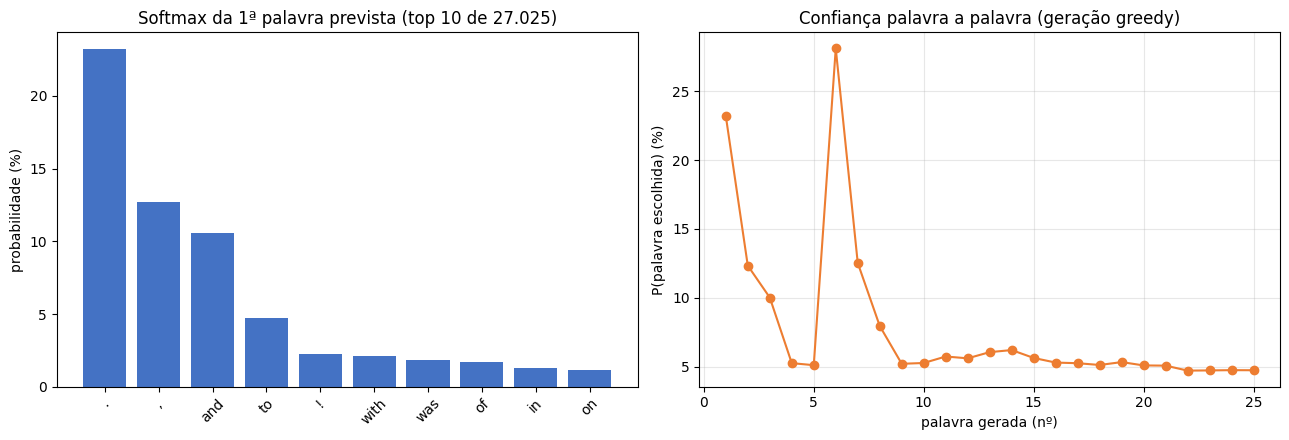

In [0]:
%python
# ==============================================================================
# STEP 14: GERAÇÃO DE TEXTO — O MODELO OLHA PARA O PROMPT E PREVÊ AS PALAVRAS
#          SEGUINTES, UMA A UMA
# ==============================================================================
# Como funciona:
#   1. O prompt inicial é tokenizado com o mesmo padrão do STEP 3.
#   2. O modelo olha para os últimos 16 tokens do contexto e produz logits.
#   3. Aplica-se a função SOFTMAX à camada de saída para extrair as
#      probabilidades de TODO o vocabulário (27.025 palavras).
#   4. Escolhe-se a palavra seguinte (greedy = mais provável; amostragem =
#      sorteio ponderado pelas probabilidades).
#   5. Adiciona-se essa palavra ao contexto e repete-se o processo até ao
#      limite de comprimento (N_PALAVRAS) ou ao token de paragem <eos>.
#
# Input:  modelo treinado (STEP 7) + vocabulário; prompt à escolha abaixo.
# Nota:   prompts com >= 16 palavras ficam dentro do que o modelo viu no
#         treino (contextos completos); prompts curtos são completados à
#         esquerda com <pad> (fora de distribuição).
# ==============================================================================

import re

import pandas as pd
import torch

TOKEN_PATTERN = "[a-z]+(?:'[a-z]+)?|[.,!?]"   # igual ao STEP 3
PAD_ID, UNK_ID, EOS_ID = 0, 1, 2

vocab_ger = {r["palavra"]: r["token_id"] for r in spark.table(VOCAB).collect()}


def tokenizar(texto):
    # mesmo padrão do STEP 3; palavras fora do vocabulário -> <unk>
    return [vocab_ger.get(t, UNK_ID) for t in re.findall(TOKEN_PATTERN, texto.lower())]


def gerar(prompt, n_palavras=25, metodo="greedy", temperatura=1.0):
    # devolve (texto gerado, ids gerados, softmax da 1ª previsão, confiança por passo)
    ids = tokenizar(prompt)
    gerados = []
    probs_primeira = None
    confianca = []
    for passo in range(n_palavras):
        ctx = ids[-CONTEXT_SIZE:]
        if len(ctx) < CONTEXT_SIZE:
            ctx = [PAD_ID] * (CONTEXT_SIZE - len(ctx)) + ctx
        x = torch.tensor([ctx], dtype=torch.long)
        with torch.no_grad():
            logits = logits_ultima(model, x)                        # (1, V)
            probs = torch.softmax(logits / temperatura, dim=-1)[0]  # softmax sobre as 27.025
        if passo == 0:
            probs_primeira = probs
        if metodo == "greedy":
            novo = int(probs.argmax())
        else:
            novo = int(torch.multinomial(probs, 1))
        if novo == EOS_ID:            # token de paragem
            break
        gerados.append(novo)
        confianca.append(float(probs[novo]))
        ids.append(novo)             # adiciona ao contexto e repete
    texto = " ".join(inv_vocab[i] for i in gerados)
    for p in [" .", " ,", " !", " ?"]:
        texto = texto.replace(p, p[1])  # pontuação colada ao texto
    return texto, gerados, probs_primeira, confianca


# --- Demonstração 1: greedy (escolhe sempre a palavra mais provável) ------------
prompt_1 = "once upon a time there was a little girl named lily . she loved to play"
texto_1, gerados_1, probs_1, conf_1 = gerar(prompt_1, n_palavras=25)
print(f"PROMPT : {prompt_1}")
print(f"GERADO : {texto_1} [{len(gerados_1)} palavras]")

top = torch.topk(probs_1, 8)
tabela = pd.DataFrame({
    "palavra": [inv_vocab[i] for i in top.indices.tolist()],
    "probabilidade_%": [round(100 * v, 2) for v in top.values.tolist()],
})
print("\nSoftmax da 1ª palavra prevista — top 8 (distribuição sobre todo o vocabulário, 27.025 palavras):")
display(tabela)

# --- Demonstração 2: amostragem (sorteio ponderado — texto mais variado) --------
prompt_2 = "tim and his dog were walking in the park when they saw a big red ball"
texto_2, _, _, _ = gerar(prompt_2, n_palavras=25, metodo="amostragem", temperatura=1.0)
print(f"\nPROMPT : {prompt_2}")
print(f"GERADO (amostragem): {texto_2}")

texto_2b, _, _, _ = gerar(prompt_2, n_palavras=25, metodo="amostragem", temperatura=1.0)
print(f"GERADO (amostragem, outra vez — repare que é diferente): {texto_2b}")

print("\nRESULTADO: o loop prevê a palavra seguinte (softmax sobre o vocabulário "
      "todo), acrescenta-a ao contexto e repete até ao limite de palavras ou ao "
      "token <eos>. O modelo ainda é subtreinado, por isso a greedy escolhe "
      "sobretudo palavras frequentes ('said', 'the', '.') — mas o mecanismo de "
      "geração autoregressiva é o mesmo dos GPT reais.")

# --- Gráfico principal: softmax da 1ª previsão + confiança ao longo da geração --
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) distribuição softmax da 1ª palavra prevista (top 10 de 27.025)
top10 = torch.topk(probs_1, 10)
palavras = [inv_vocab[i] for i in top10.indices.tolist()]
valores = [100 * v for v in top10.values.tolist()]
ax1.bar(palavras, valores, color="#4472C4")
ax1.set_title("Softmax da 1ª palavra prevista (top 10 de 27.025)")
ax1.set_ylabel("probabilidade (%)")
ax1.tick_params(axis="x", rotation=45)

# (b) confiança do modelo (P da palavra escolhida) ao longo da geração greedy
ax2.plot(range(1, len(conf_1) + 1), [100 * p for p in conf_1],
         marker="o", color="#ED7D31")
ax2.set_title("Confiança palavra a palavra (geração greedy)")
ax2.set_xlabel("palavra gerada (nº)")
ax2.set_ylabel("P(palavra escolhida) (%)")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# CONCLUSÃO — MiniGPT-TinyStories: Next-Word Prediction do Zero

## O que foi construído

Um **mini-GPT completo, construído do zero** (sem bibliotecas de transformers), treinado no dataset TinyStories da Hugging Face, inteiramente em Databricks sobre compute CPU serverless:

* **Pipeline de dados**: ingestão HF → Delta bronze (2.141.709 histórias) → tokenização word-level (vocabulário de 27.025 tokens, freq ≥ 5) → pares contexto→alvo (16 tokens de contexto, 3,7M pares de treino).
* **Modelo**: Transformer decoder-only com 4,25M parâmetros — embeddings de token e posição, 4 blocos pre-LN com atenção causal multi-cabeça (4 cabeças, d=128) e MLP 512, LayerNorm final, weight tying na cabeça de saída, inicialização estilo GPT-2 (std 0,02).
* **Treino**: AdamW (lr 1e-3, lote 512), 350 passos em CPU com orçamento de tempo, tracking em MLflow, modelo e métricas persistidos.
* **Geração autoregressiva**: prompt → softmax sobre as 27.025 palavras → palavra escolhida → acrescentada ao contexto → repetir até ao limite ou `<eos>`, com greedy e amostragem.

## Números principais

| Métrica | Início | Fim |
| --- | --- | --- |
| Perda de validação | 10,20 (≈ ln V) | **5,01** |
| Perplexidade | 27.025 (aleatório) | **150** |
| Precisão top-1 (validação) | ~0% | **15,8%** |
| P(palavra correta) média | 0,004% | **5,3%** |
| Ranking mediano da palavra correta | — | **14º de 27.025** |

## Descobertas da investigação (Etapa 5)

1. **Contexto**: precisão sobe de 4,5% (1 palavra de contexto) para 15,8% (16 palavras) — mais contexto = previsões melhores.
2. **Evolução**: P(palavra correta) no probe fixo subiu 0,0004 → 0,0015 ao longo do treino, sempre acima do aleatório; perplexidade 413 → 159.
3. **Dificuldade**: correlação 0,84 entre frequência e facilidade; mais fáceis: pontuação e stopwords; mais difíceis: palavras frequentes mas dependentes do contexto («all», «fun», «back»).
4. **Gramática vs coocorrência**: baralhar a ordem das palavras do contexto derrubou P(correta) em −63% — o modelo aprendeu **estrutura/ordem**, não é um contador de coocorrências.
5. **Dados vs computação**: com a mesma computação, mais dados **piorou** (25k: 5,62 vs 200k: 5,72) — repetição consolida; mais dados só se traduz em vantagem com mais treino (350 passos: 5,01).

## Lições de engenharia

* A inicialização por defeito do `nn.Embedding` (std 1) dá perda inicial ~91; com std 0,02 (GPT-2) a perda inicial ≈ ln(V) — o comportamento esperado.
* Máscaras causais fixas rebentam com sequências mais curtas: fatiar a máscara (`mask[:T, :T]`) torna o modelo robusto a qualquer comprimento.
* Em CPU serverless, aplicar a cabeça de saída só na última posição poupa ~16× FLOPs sem mudar a arquitetura.

## Limitações e próximos passos

Modelo subtreinado por limite de CPU (350 passos ≈ 179k exemplos): gera frases com loops repetitivos, típico de undertraining. Próximos passos: treinar em GPU até convergência (milhões de passos sobre os 3,7M pares), scheduler de learning-rate, tokenização BPE e beam search / top-k sampling.